In [4]:
import requests
import mlflow

import numpy as np

import tensorflow as tf
from tensorflow import keras

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

import json
import pickle
import os

In [1]:
ORCHESTRATOR = "http://vm.fured.cloud.bme.hu:11686/worker/orchestrator"

TEST_FILE_PATH = "../02_data/course_test.npz"

AUT_FILE_PATH = "../05_test/basic_auth_creds.json"

In [3]:
test_data = np.load(TEST_FILE_PATH)
x_test = test_data["x_test"]
y_test = test_data["y_test"]

In [7]:
with open(AUT_FILE_PATH, "r") as f:
    auth_data = json.load(f)

os.environ["MLFLOW_TRACKING_USERNAME"] = auth_data["user"]
os.environ["MLFLOW_TRACKING_PASSWORD"] = auth_data["password"]

## Evaluate current model

In [15]:
model_resource = requests.get(f"{ORCHESTRATOR}/get_model")
model_resource_dict = model_resource.json()
model_resource_dict

ConnectionError: HTTPConnectionPool(host='vm.fured.cloud.bme.hu', port=11686): Max retries exceeded with url: /worker/orchestrator/get_model (Caused by NewConnectionError("HTTPConnection(host='vm.fured.cloud.bme.hu', port=11686): Failed to establish a new connection: [Errno 111] Connection refused"))

In [ ]:
mlflow.set_tracking_uri(model_resource_dict["model_host"])
nn = mlflow.tensorflow.load_model(model_resource_dict["model_uri"])
perf = nn.evaluate(x_test, y_test)

W0000 00:00:1774960919.903192   32690 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...
/home/madbiker/miniconda3/envs/tf_env/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 14 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7158 - loss: 0.5933  


## Start training:

### **FedAvg aggregation**

In [ ]:
#ORCHESTRATOR_URI = "http://127.0.0.1:8000"
ORCHESTRATOR_URI = "http://vm.fured.cloud.bme.hu:19953/worker/orchestrator"

EPOCHS = 5

TEST_FILE_PATH = "../02_data/course_test.npz"

In [7]:
aggregator = {
    "processors": ["http://data-processor-0:8000", "http://data-processor-1:8000"],
    "aggregators": ["http://aggregator:8000"],
    "train_data_uri": ["data/train_data.npz", "data/train_data.npz"],
    "aggregation_algorithm": "fedavg"
}

In [12]:
test_loss = []
for i, e in enumerate(range(EPOCHS)):
    print(f"training round {i}")
    model = requests.get(f"{ORCHESTRATOR_URI}/get_model")
    model = model.json()
    
    if "model_uri" in model:
        os.environ["MLFLOW_TRACKING_USERNAME"] = model["model_username"]
        os.environ["MLFLOW_TRACKING_PASSWORD"] = model["model_password"]
        mlflow.set_tracking_uri(model["model_host"])
        #mlflow.set_tracking_uri("http://127.0.0.1:5101")
        #mlflow.set_tracking_uri("http://vm.fured.cloud.bme.hu:9860")
        nn = mlflow.tensorflow.load_model(model["model_uri"])
        perf = nn.evaluate(x_test, y_test)
        test_loss.append(perf[0])
    
    training = requests.post(f"{ORCHESTRATOR_URI}/start_training", json=aggregator)   

training round 0
training round 1
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7158 - loss: 0.6413  
training round 2
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7158 - loss: 0.5360  
training round 3
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7158 - loss: 0.5397  
training round 4
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7268 - loss: 0.5366  


In [22]:
model = requests.get(f"{ORCHESTRATOR_URI}/get_model")

In [23]:
model.json()

{'model_host': 'http://localhost:5101',
 'model_uri': 'models:/m-96b88aeb94824fad828ae8acde2c5d34'}

In [24]:
with open("../02_data/fl_losses.pickle", "wb") as f:
    pickle.dump({
        "test_loss": test_loss
    }, f)

Text(0.5, 0, 'epochs')

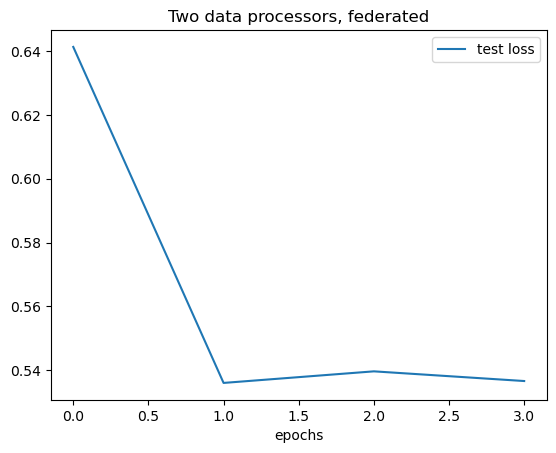

In [13]:
import matplotlib.pyplot as plt

plt.plot(test_loss, label="test loss")
plt.legend()
plt.title("Two data processors, federated")
plt.xlabel("epochs")
#plt.ylim(0, 10)

In [26]:
model

<Response [200]>

In [27]:
y_pred = nn.predict(x_test)>0.5

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


In [28]:
with open("../02_data/for_fed_confmtx.pickle", "wb") as f:
    output_dict = {
        "y_pred_fed": y_pred
    }
    pickle.dump(output_dict, f)

In [29]:
with open("../02_data/for_fed_confmtx.pickle", "rb") as f:
    input_dict = pickle.load(f)
    
y_pred = input_dict["y_pred_fed"]

Text(0.5, 1.0, 'Confusion matrix\nfederated system')

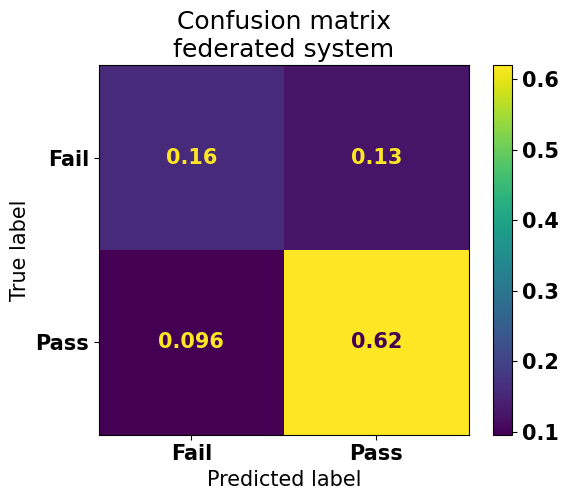

In [30]:
cm = confusion_matrix(y_test, y_pred, labels=[False, True], normalize="all")

font = {'weight' : 'bold', 'size'   : 15}
plt.rc('font', **font)

disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=[False, True])
disp.plot()
plt.xticks(ticks=[0,1], labels=["Fail", "Pass"])
plt.yticks(ticks=[0,1], labels=["Fail", "Pass"])
plt.title("Confusion matrix\nfederated system")

### **DeltaRep aggregation**

In [39]:
ORCHESTRATOR_URI = "http://127.0.0.1:8000"
#ORCHESTRATOR_URI = "http://vm.fured.cloud.bme.hu:3917"

EPOCHS = 2

TEST_FILE_PATH = "../02_data/course_test.npz"

In [40]:
aggregator = {
    "processors": ["http://data-processor-0:8000", "http://data-processor-1:8000"],
    "aggregators": ["http://aggregator:8000"],
    "train_data_uri": ["data/train_data.npz", "data/train_data.npz"],
    "aggregation_algorithm": "deltarep"
}

In [44]:
test_loss = []
for i, e in enumerate(range(EPOCHS)):
    print(f"training round {i}")
    model = requests.get(f"{ORCHESTRATOR_URI}/get_model")
    model = model.json()
    
    if "model_uri" in model:
        mlflow.set_tracking_uri(model["model_host"])
        #mlflow.set_tracking_uri("http://127.0.0.1:5101")
        #mlflow.set_tracking_uri("http://vm.fured.cloud.bme.hu:9860")
        nn = mlflow.tensorflow.load_model(model["model_uri"])
        perf = nn.evaluate(x_test, y_test)
        test_loss.append(perf[0])
    
    training = requests.post(f"{ORCHESTRATOR_URI}/start_training", json=aggregator)   

training round 0
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7158 - loss: 0.5214  
training round 1
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7541 - loss: 0.5062  
